# Lab 2.1 Clustering

**From Lab 1 to Lab 2.** In Lab 1 we turned text into vectors (Count, TF-IDF, Word2Vec, Doc2Vec). Now we use those vectors to **learn**: here we group documents **without labels** (clustering); in Lab 2.2 and 2.3 we predict labels (classification).

Clustering is an essential technique in machine learning and data analysis used to group similar items or data points together. Unlike supervised learning, clustering is an unsupervised learning technique, meaning it does not require labeled data. Instead, clustering algorithms analyze the inherent structure of data, helping to reveal natural groupings or patterns within it.

### Why Clustering?
Clustering has a wide range of applications in various fields, such as:

- **Market Segmentation:** Grouping customers based on purchasing behavior or demographics to better tailor marketing strategies.
- **Image Segmentation:** Breaking down an image into distinct regions for tasks like object detection and classification.
- **Anomaly Detection:** Identifying outliers or unusual patterns in data, such as fraud detection in financial transactions.
- **Recommendation Systems:** Grouping similar items or users together to make personalized recommendations, such as on streaming platforms or e-commerce sites.

Don't forget to move the folder to your drive to be able to use it!

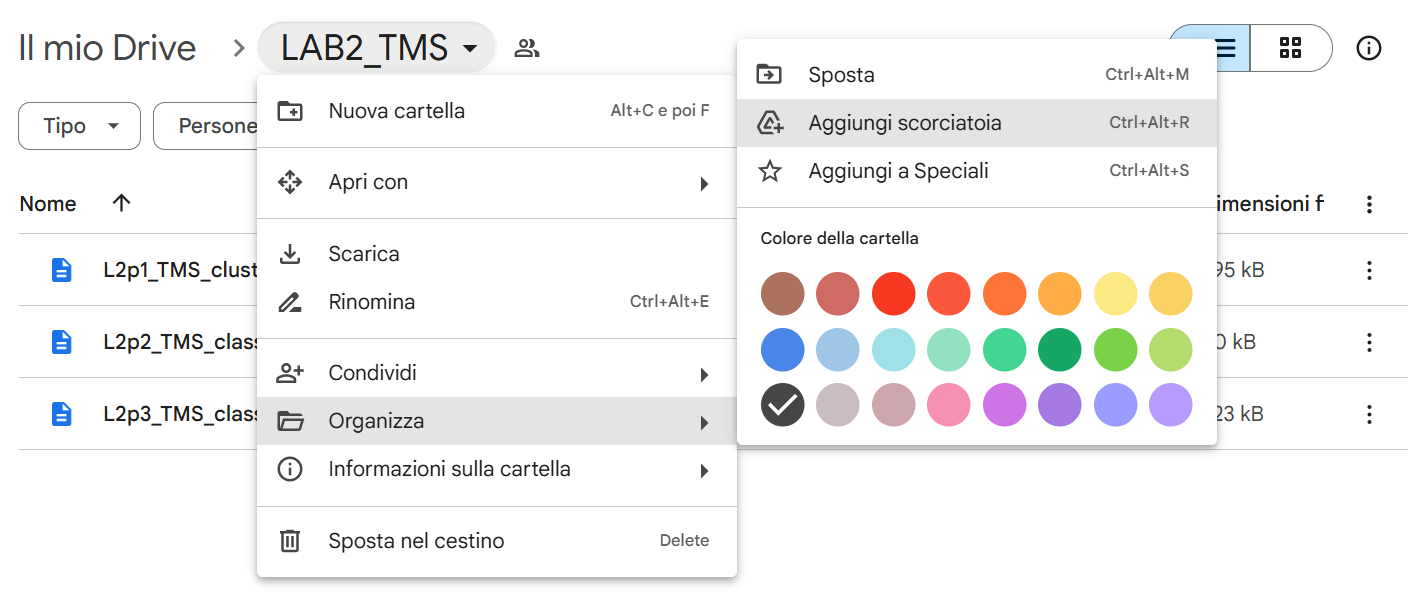

## K-Means

**📎 From the slide to the code** · slide *K-Means*

| In the slide | In the code |
|---|---|
| The 4 steps: init, assign, update, repeat | `KMeans(n_clusters=k).fit(X)` does all of them |
| k is chosen in advance | `n_clusters=2` |
| The result depends on the starting centroids | `n_init=100`: 100 different starts, the best one is kept |

K-Means is a widely-used unsupervised machine learning algorithm for clustering data into groups based on similarity. It is simple, efficient, and versatile, making it a popular choice for exploratory data analysis and segmentation tasks.

The goal of K-Means is to partition a dataset into k distinct clusters, where each data point belongs to the cluster with the nearest centroid (a central point representing the cluster). The algorithm works iteratively to refine these centroids and assign points to the closest cluster, minimizing the intra-cluster variance (the sum of squared distances between points and their cluster centroid).

#### Key Steps in K-Means:
- **Initialization:** Choose k initial cluster centroids (randomly or using heuristics).
- **Assignment:** Assign each data point to the nearest centroid based on a distance metric (commonly Euclidean distance).
- **Update:** Recalculate the centroids by averaging the data points assigned to each cluster.
- **Iteration:** Repeat the assignment and update steps until the centroids stabilize or a maximum number of iterations is reached.


K-Means is used in various domains, including: customer segmentation, image compression, anomaly detection, and document clustering.
While powerful, K-Means has limitations, such as sensitivity to the initial choice of centroids and difficulty handling non-spherical clusters. Despite these challenges, its simplicity and effectiveness make it a cornerstone of clustering techniques in machine learning.

In [1]:
!pip install gdown

In [2]:
!gdown 'https://drive.google.com/uc?id=1SwQEuHyO2A9hfSK2rdRH0J-YQ426U_20'

Downloading...
From: https://drive.google.com/uc?id=1SwQEuHyO2A9hfSK2rdRH0J-YQ426U_20
To: /content/spam.csv
100% 479k/479k [00:00<00:00, 23.3MB/s]


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# spam.csv: one SMS per row, 'text' and 'target' (spam / ham)
spam_data = pd.read_csv('spam.csv')

spam_data['target'] = np.where(spam_data['target'] == 'spam', 1, 0)   # spam = 1, ham = 0
print(spam_data.head(10))

X, y = spam_data['text'], spam_data['target']
X_train, X_test, y_train, y_test = train_test_split(
    spam_data['text'], spam_data['target'], random_state=0
)

                                                text  target
0  Go until jurong point, crazy.. Available only ...       0
1                      Ok lar... Joking wif u oni...       0
2  Free entry in 2 a wkly comp to win FA Cup fina...       1
3  U dun say so early hor... U c already then say...       0
4  Nah I don't think he goes to usf, he lives aro...       0
5  FreeMsg Hey there darling it's been 3 week's n...       1
6  Even my brother is not like to speak with me. ...       0
7  As per your request 'Melle Melle (Oru Minnamin...       0
8  WINNER!! As a valued network customer you have...       1
9  Had your mobile 11 months or more? U R entitle...       1


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Given: TF-IDF vectors of the SMS, as in Lab 1 (the vocabulary is learned on the training set)
vectorizer = TfidfVectorizer()
X_train_transformed = vectorizer.fit_transform(X_train)
X_test_transformed = vectorizer.transform(X_test)
print(X_train_transformed.shape)

(4179, 7354)


## Agglomerative clustering

**📎 From the slide to the code** · slide *K-Means vs Agglomerative / Agglomerative*

| In the slide | In the code |
|---|---|
| Merge the two closest clusters, again and again | `AgglomerativeClustering(n_clusters=5, linkage="ward")` |
| Stop when n_clusters groups are left | `n_clusters=5` |
| Needs dense vectors | `fit_predict(X.toarray())` |
| The merges form a tree: the dendrogram | `linkage(...)` and `dendrogram(...)` in the cell below |

Agglomerative clustering is **hierarchical**: every document starts as its own cluster, then at each step the two **closest** clusters are merged, until only `n_clusters` are left. K-Means instead is **partitional**: it splits the data into k flat groups in one go.

How far apart are two clusters? It depends on the **linkage**:
- **single**: the closest pair of points (one stray point can chain two clusters);
- **complete**: the farthest pair of points;
- **average**: the mean distance over all pairs;
- **ward** (scikit-learn default): the merge that least increases the variance inside the clusters.

The merges form a tree, the **dendrogram**: the leaves are the documents, the height of each join is the distance at which two clusters were merged. **Cutting** the tree at a height gives the clusters: cut high → few, big clusters; cut low → many, small clusters. So, unlike K-Means, the number of clusters can be chosen **after** looking at the tree (in scikit-learn we still pass `n_clusters`, i.e. where to cut).

**Cost:** it compares all pairs of documents, so it is fine for 4,179 SMS but slow for millions; K-Means is much faster.

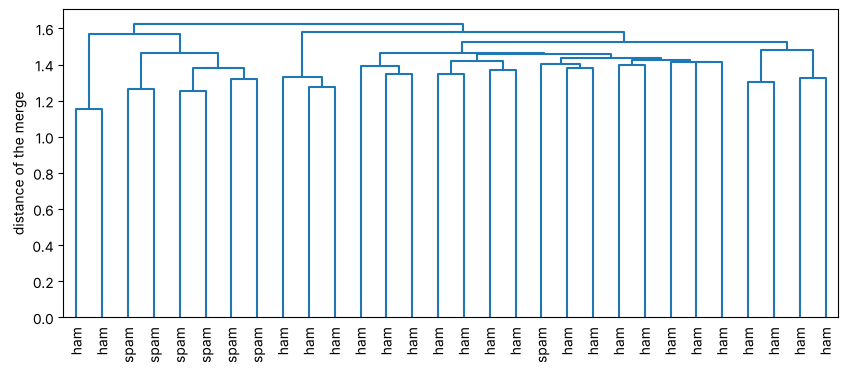

In [5]:
# The dendrogram of 30 SMS: each leaf is an SMS (spam / ham), each join is a merge
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

sample = X_train_transformed[:30].toarray()            # 30 SMS, dense TF-IDF vectors
names = ['spam' if t == 1 else 'ham' for t in y_train[:30]]

merges = linkage(sample, method='ward')               # the same 'ward' linkage as AgglomerativeClustering
plt.figure(figsize=(10, 4))
dendrogram(merges, labels=names, leaf_rotation=90)
plt.ylabel('distance of the merge')
plt.show()

## Evaluating clusters

**📎 From the slide to the code** · slide *Evaluating clusters / Cluster metrics*

| In the slide | In the code |
|---|---|
| Compare the clusters with the true labels | `v_measure_score(y_true, y_clus)`: true labels first |
| ARI: 1 = perfect, 0 = random, < 0 = worse | `adjusted_rand_score(y_true, y_clus)` |
| Purity: share of the majority class | `purity_score(y_true, y_clus)` (given below) |

Both V-Measure Score and Adjusted Rand Score (ARS) are metrics used to evaluate clustering performance by comparing the resulting clusters to a ground-truth labeling. However, they measure different aspects of clustering quality and have distinct characteristics.

### 1. V-Measure Score
The V-Measure Score is an information-theoretic measure that evaluates the balance between two properties of clustering:

- **Homogeneity:** Ensures that each cluster contains only members of a single class (ground-truth label).
- **Completeness:** Ensures that all members of a single class are assigned to the same cluster.

The V-Measure Score is the harmonic mean of homogeneity (H) and completeness (C):

$$
V\text{-}Measure=2\frac{H \cdot C}{H+C}
$$

It's range is [0,1], where 1 means perfect clustering (both homogeneity and completeness are maximized) and 0 means no correspondence between clusters and ground truth.

**Advantages:** Useful for interpreting how well the clusters align with labels in terms of purity and coverage.
Independent of the absolute number of clusters, focusing instead on the relationship between labels and clusters.
**Disadvantages:** Does not account for random chance in clustering assignments.

### 2. Adjusted Rand Score (ARS)
The Adjusted Rand Score evaluates the similarity between two clusterings (e.g., predicted clusters and ground truth) by counting pairs of points that are consistently assigned to the same or different clusters in both labelings. It adjusts for chance by considering the expected similarity of random clusterings. To understand the ARS, we should first understand the Rand Index

Given two sets $X$ and $Y$, where each set is divided up into clusters, we define the rand index as:
$$
R = \frac{TP+TN}{TP+TN+FP+FN}
$$
so we can think of this as the number of "disagreements" between $X$ and $Y$.
We then adjust this score by finding the "expected index" (what we would expect the rand index to be in the case of random selection).

$$
ARS
= \frac{Index-Expected Index}{Max Index-Expected Index}
$$

with range [−1,1], where 1 means perfect clustering agreement with ground truth, 0 means clustering is no better than random and negative values that clustering is worse than random chance.

**Advantages:** Adjusts for random chance, providing a robust measure of clustering quality. Useful for comparing clustering methods even when the number of clusters differs significantly.
**Disadvantages:** Requires the number of clusters to match (or approximate) the ground truth labels, making it less flexible than the V-Measure Score.

### 3. Purity
The share of the **majority class** in each cluster, summed over the clusters and divided by the number of documents. Simple, but careful: with one cluster per document the purity is 1, and with very unbalanced classes (87% ham) even a useless clustering has a high purity.

In [6]:
# Given: purity = for each cluster, how many documents belong to its majority class; sum, then divide by the total
def purity_score(true_labels, predicted_labels):
    table = pd.crosstab(np.asarray(predicted_labels), np.asarray(true_labels))   # rows = clusters, columns = classes
    return table.max(axis=1).sum() / len(true_labels)

# Exercise 1.1: K-Means vs Agglomerative on the SMS

Use the TF-IDF vectors of the training SMS (`X_train_transformed`) and their true labels (`y_train`: 1 = spam, 0 = ham). The labels are used **only to evaluate** the clusters, not to build them.

1. Cluster the SMS with `KMeans` into **2** clusters (as many as the classes). Compute V-measure, ARI and purity (`purity_score`).
2. Cluster them with `AgglomerativeClustering(linkage="ward")`, first with **5** clusters, then with **2**. Compute the same metrics.
3. Which comparison between K-Means and Agglomerative is fair? Which method separates spam from ham better?
4. With 5 clusters, look at the SMS inside each cluster (`X_train[labels == c]`): what do the small clusters contain?

*Hint: `KMeans(n_clusters=2, n_init=100, random_state=42).fit_predict(X)`; `AgglomerativeClustering` wants a dense matrix: `X_train_transformed.toarray()`. To see the most frequent SMS of a cluster: `X_train[labels == c].value_counts().head()`.*

In [7]:
# Your code here

## Game of Thrones Clustering

**📎 From the slide to the code** · slide *Visualizing clusters*

| In the slide | In the code |
|---|---|
| Project TF-IDF to 2D, only to look at it | `TruncatedSVD(n_components=2).fit_transform(X)` |
| SVD: linear, works on sparse TF-IDF | the first plot: the characters overlap |
| t-SNE: keeps neighbours close, good for pictures | `TSNE(n_components=2, init='random', learning_rate='auto')` |

We are going use the techniques we've developed so far to understand which character of the GOT books is closer to which. We will show a few visualization techniques, no need to memorize them all, and a method to estimate the number of clusters, called the [Elbow method](https://www.scikit-yb.org/en/latest/api/cluster/elbow.html). Each document is a **chapter** of the first four books: in these books every chapter is told from the point of view of one character, and its title is the name of that character. The text has already been lowercased, without punctuation and stop words (as in Lab 1). We cluster the chapters by their TF-IDF vectors and check if the clusters match the characters.

We will be using some dimensionality reduction. Recall what tf-idf is from lab 1:

"Term Frequency-Inverse Document Frequency. $TF(w,d)$ is the number of times word $w$ appears in document $d$. $IDF(w)$ is the rarity of the word in the corpora (collection of documents), calculated as
$$
IDF(w) = log \frac{n}{df(w)}
$$
Where $n$ is the number of documents and $df(w)$ is the number of documents containing $w$. We then calculate the TF-IDF weight, which shows how important a word $w$ is to a document $d$, as follows $$TFIDF(w,d) = TF(w,d)\times IDF(w)$$"

Vectorising a sequence with tf-idf involves finding the tf-idf weight for each term in a vocabulary. This means the vectors are quite *sparse*, lots of the values are 0. As such, we use **truncated SVD** for dimensionality reduction: it keeps the $k$ directions (combinations of words) that best approximate the TF-IDF matrix, as in LSA, and discards the rest. Here we use it only to **look** at the data in 2D or 3D.

In [14]:
# The chapters of the first 4 books, one CSV per book (Name, Chapter, Text), from the course Drive folder
from google.colab import drive
drive.mount('/content/gdrive')

base_path = 'gdrive/MyDrive/Labs/LAB2_TMS/data/'   # use the path of your Drive folder

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

In [16]:
# one row per chapter: the character of the chapter (Name), its number for that character (Chapter),
# and the text in lowercase, without punctuation and stop words (Text)
got1 = pd.read_csv(f'{base_path}got1_nostops.csv', index_col=0)
got2 = pd.read_csv(f'{base_path}got2_nostops.csv', index_col=0)
got3 = pd.read_csv(f'{base_path}got3_nostops.csv', index_col=0)
got4 = pd.read_csv(f'{base_path}got4_nostops.csv', index_col=0)
got = pd.concat([got1, got2, got3, got4])

In [17]:
got.head()

,Name,Chapter,Text
0,Intro,1,game thrones book one song ice fire george r r...
1,Prologue,1,start back gared urged woods began grow dark a...
2,Bran,1,morning dawned clear cold crispness hinted end...
3,Catelyn,1,catelyn never liked godswood born tully riverr...
4,Daenerys,1,brother held gown inspection beauty touch go c...


In [18]:
got.groupby('Name').size().sort_values()

Name
Epilogue                      1
The Queenmaker                1
The Prophet                   1
The Princess In The Tower     1
The Kraken's Daughter         1
The Iron Captain              1
The Drowned Man               1
The Soiled Knight             1
The Reaver                    1
The Captain Of Guards         1
Appendix                      3
Intro                         4
Prologue                      4
Theon                         6
Brienne                       8
Davos                         9
Cersei                       10
Samwell                      10
Eddard                       15
Jaime                        16
Bran                         18
Daenerys                     21
Sansa                        24
Catelyn                      25
Jon                          29
Arya                         31
Tyrion                       35
dtype: int64

In [19]:
names = ['Arya', 'Bran', 'Brienne', 'Catelyn', 'Cersei',
         'Daenerys', 'Davos', 'Eddard', 'Jaime', 'Jon',
         'Samwell', 'Sansa',  'Theon', 'Tyrion']

got = got[got.Name.isin(names)]

In [20]:
cdict = {'Jon' : 'black',
         'Samwell' : 'tab:purple',
         'Eddard': 'tab:brown',
         'Arya' : 'lime',
         'Catelyn' : 'tab:green',
         'Bran' : 'tab:blue',
         'Sansa' : 'tab:pink',
         'Theon' : 'tab:cyan',
         'Brienne' : 'tab:gray',
         'Davos' : 'tab:olive',
         'Tyrion' : 'tab:red',
         'Jaime' : 'goldenrod',
         'Cersei' : 'gold',
         'Daenerys' : 'tab:orange',}

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

In [22]:
%%time
documents = list(got.Text)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(documents)

CPU times: user 315 ms, sys: 8.01 ms, total: 323 ms
Wall time: 329 ms


In [23]:
svd = TruncatedSVD(n_components=2)
data = svd.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]

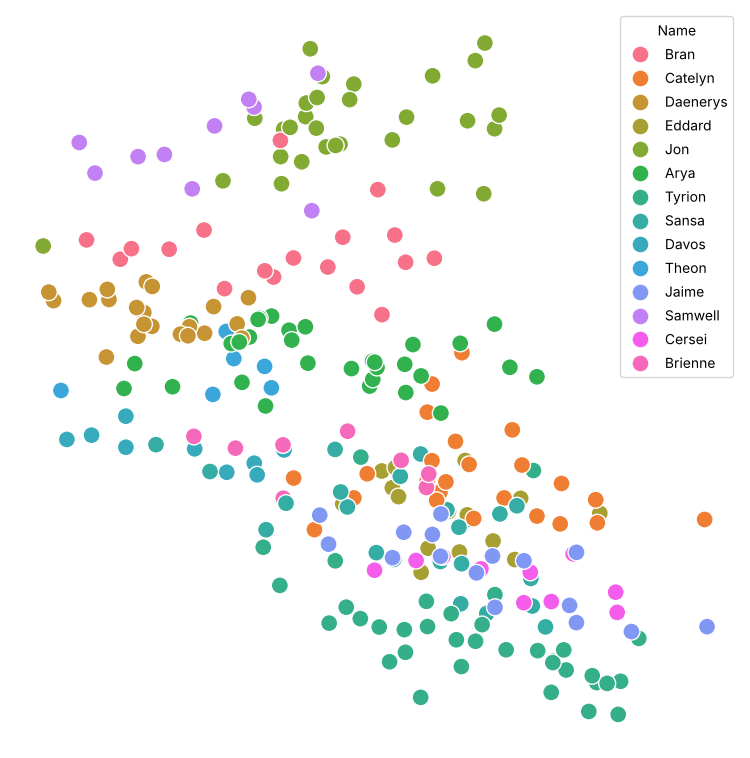

In [24]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x = scatter_x, y=scatter_y, hue=got.Name, s=150)
plt.tight_layout()
plt.axis('off')
plt.show()

In [25]:
# 3D viz
svd = TruncatedSVD(n_components=3)
data = svd.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]
scatter_z = data[:, 2]
px.scatter_3d(x=scatter_x, y=scatter_y, z=scatter_z, color=got.Name)

T-SNE is another approach to visualising high-dimensional data (https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)

In [26]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='random', learning_rate='auto')
data = tsne.fit_transform(X)
tsne_2d = data  # saved: the 3D t-SNE below overwrites scatter_x / scatter_y
scatter_x = data[:, 0]
scatter_y = data[:, 1]

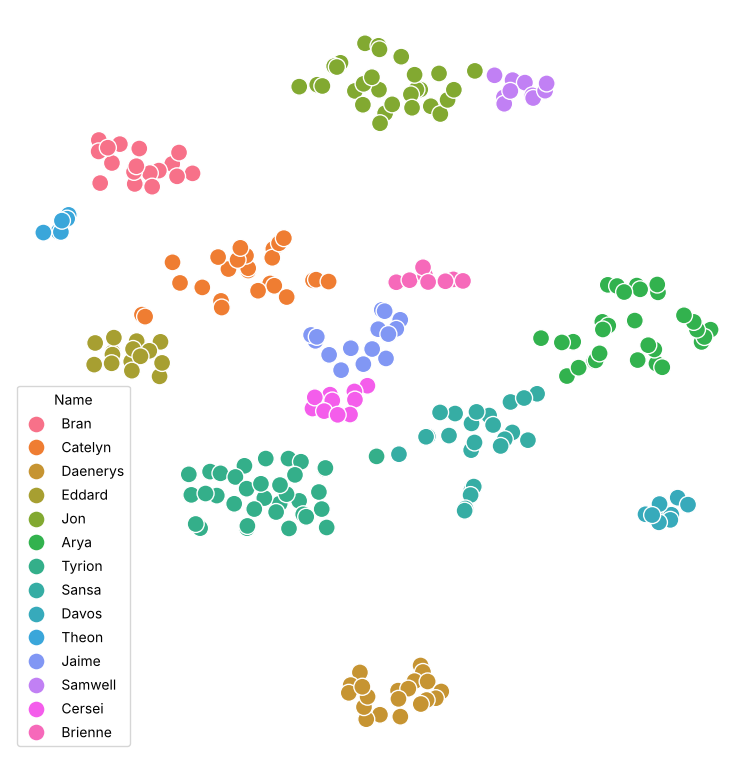

In [27]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x = scatter_x, y=scatter_y, hue=got.Name, s=150)
plt.tight_layout()
plt.axis('off')
plt.show()

In [28]:
# 3D viz
tsne = TSNE(n_components=3, init='random', learning_rate='auto')
data = tsne.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]
scatter_z = data[:, 2]
px.scatter_3d(x=scatter_x, y=scatter_y, z=scatter_z, color=got.Name)

We now evaluate the clustering of the chapters. We already know the Rand index and the V-measure (with homogeneity and completeness); `score_clustering` also prints the **Adjusted Mutual Info** and the **Fowlkes-Mallows** score (both: 1 = the clusters match the characters, ≈ 0 = random).

In [29]:
from sklearn.metrics import (rand_score, adjusted_mutual_info_score,
                             homogeneity_score, completeness_score,
                             v_measure_score, fowlkes_mallows_score)

def score_clustering(true_labels, predicted_labels):
  d = {
      "Rand index": rand_score(true_labels, predicted_labels),
      "Adjusted Mutual Info": adjusted_mutual_info_score(true_labels, predicted_labels),
      "Homogeneity": homogeneity_score(true_labels, predicted_labels),
      "Completeness": completeness_score(true_labels, predicted_labels),
      "V measure": v_measure_score(true_labels, predicted_labels),
      "Fowlkes Mallows": fowlkes_mallows_score(true_labels, predicted_labels),
  }
  for k, v in d.items():
    print(f"{k:21s}: {v}")

In [30]:
from sklearn.cluster import KMeans

# one cluster per character: k = 14
kmeans = KMeans(n_clusters=len(names), random_state=1)
labels_pred = kmeans.fit_predict(X)

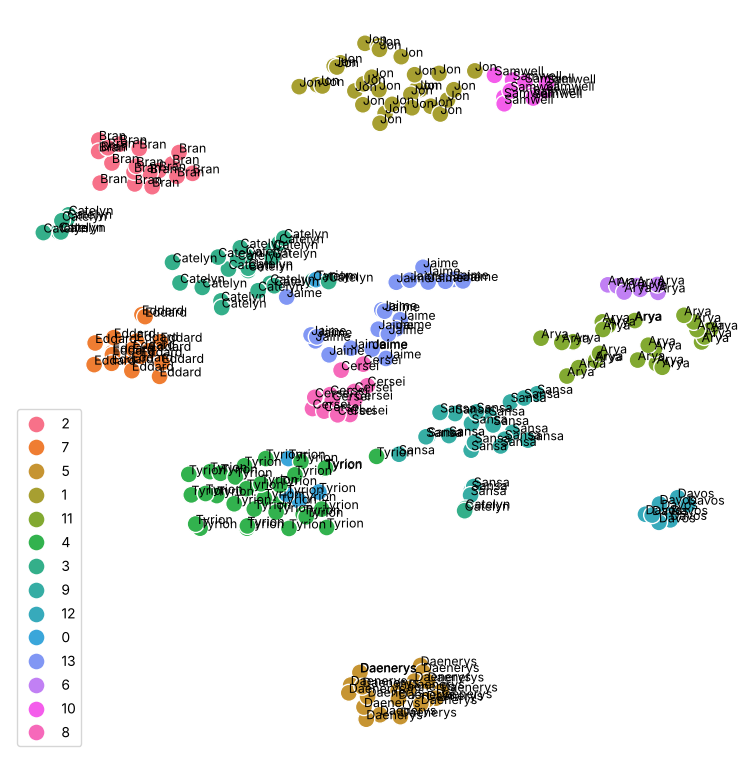

In [31]:
# Cluster ids (0, 1, 2, ...) are arbitrary: cluster 0 is NOT "Arya".
# We name each cluster after the character that appears most often in it
# (two clusters can get the same name: that is information too!).
cluster_to_name = pd.Series(got.Name.values).groupby(labels_pred).agg(lambda s: s.mode()[0])
predicted_labels_as_names = [cluster_to_name[c] for c in labels_pred]

# We plot on the 2D t-SNE map computed above (tsne_2d)
plt.figure(figsize=(8, 8))
sns.scatterplot(x=tsne_2d[:, 0], y=tsne_2d[:, 1], hue=labels_pred.astype(str), s=150, legend="full")
for (x, y), name in zip(tsne_2d, predicted_labels_as_names):
    plt.text(x, y, name, fontsize=9)
plt.tight_layout()
plt.axis('off')
plt.show()

In [32]:
score_clustering(got.Name, labels_pred)

Rand index           : 0.9750425583657587
Adjusted Mutual Info : 0.8997266164606683
Homogeneity          : 0.9162165359237515
Completeness         : 0.9121538277219804
V measure            : 0.9141806680771116
Fowlkes Mallows      : 0.8511804436093292


## Choosing k

**📎 From the slide to the code** · slide *Choosing k*

| In the slide | In the code |
|---|---|
| Inertia always decreases: look for the elbow | `metric='distortion'` (the default) |
| Silhouette: take the maximum, not an elbow | `metric='silhouette'` |
| The best k | `visualizer.k_values_[np.argmax(visualizer.k_scores_)]` |

K-Means needs k in advance. The `KElbowVisualizer` of the Yellowbrick library fits K-Means for every k in a range and plots a score for each k:
- **Inertia** (`metric='distortion'`, the default): how close the points are to their centroid. It **always decreases** when k grows, so we look for the **elbow**, the k where the gain slows down.
- **Silhouette** (`metric='silhouette'`): for each point, is it closer to its own cluster than to the nearest other cluster? From −1 to 1, **higher is better**: the best k is the **maximum** of the curve, not an elbow.

Careful: the visualizer always marks an "elbow" on the plot (`visualizer.elbow_value_`), also when the metric is the silhouette. For the silhouette, look at the **maximum** instead.

In [33]:
from yellowbrick.cluster import KElbowVisualizer
# See https://www.scikit-yb.org/en/latest/api/cluster/elbow.html

# Exercise 1.2: choosing k for the GoT chapters

The next cell is given: it computes the silhouette for k = 2…19 (it takes a while).

1. Which k does the plot mark as "elbow" (`visualizer.elbow_value_`)? Which k has the **highest** silhouette (`visualizer.k_values_`, `visualizer.k_scores_`)?
2. Cluster the chapters with K-Means using the elbow k, then the best-silhouette k, and compare them with `score_clustering(got.Name, ...)` and with k = 14 (above).
3. Which k would you choose, and why is the "elbow" misleading here?

*Hint: `np.argmax(visualizer.k_scores_)` is the position of the highest score in the list.*

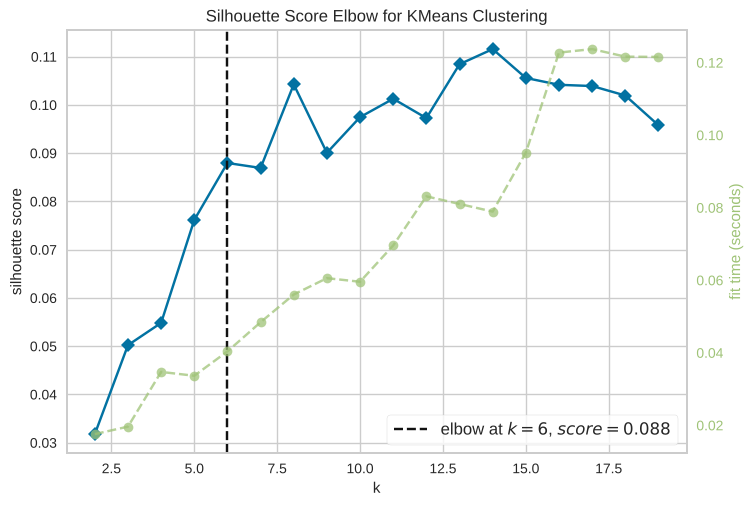

CPU times: user 3.1 s, sys: 27.8 ms, total: 3.12 s
Wall time: 2.6 s


<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [34]:
%%time
# Given: K-Means for k = 2...19, silhouette score for each k (this will take a while)
model = KMeans(random_state=1)
# force_model=True: recent scikit-learn versions are not recognised as 'clustering' by Yellowbrick, without it you get an error
visualizer = KElbowVisualizer(model, k=(2, 20), metric='silhouette', force_model=True)
visualizer.fit(X)
visualizer.show()

In [35]:
# Your code here

## K-Means from scratch

**📎 From the slide to the code** · slide *K-Means*

| In the slide | In the code |
|---|---|
| 1. Init: k random points as centroids | `X[rng.choice(len(X), k, replace=False)]` |
| 2. Assign: each point → nearest centroid | `np.argmin(distances, axis=0)` |
| 3. Update: centroid = mean of its points | `X[labels == k].mean(axis=0)` |
| 4. Repeat until nothing moves | `np.allclose(self.centroids, new_centroids)` |

Let's look at how K-Means is implemented: it is simpler than it looks. The code follows [Juan C Olamendy](https://medium.com/@juanc.olamendy/back-to-basics-mastering-k-means-clustering-with-numpy-ae7e6f1cb9a3).

# Exercise 1.3: K-Means from scratch

The next cells are given: a toy dataset with 3 groups of points (`X_toy`), and the class `KMeansScratch` with **3 blanks** (`___`), one for each step of the algorithm.

1. Complete the 3 blanks: **init** (k random points of the data as centroids), **assign** (each point → nearest centroid), **update** (each centroid = mean of its points).
2. Run it on `X_toy` with `max_iters=1`, then `max_iters=3`, and plot the points coloured by cluster with the centroids. What changes?
3. Compare your centroids with the ones of scikit-learn's `KMeans(n_clusters=3)` (`.cluster_centers_`) and with the true centres of the groups `[2, 2]`, `[8, 3]`, `[3, 6]`.

*Hint: `rng.choice(n, k, replace=False)` gives k different positions out of n; `np.argmin(D, axis=0)` gives, for each column (point), the row (centroid) with the smallest value.*

In [41]:
# Toy data creation
# (we use X_toy, so the GoT matrix X above is not overwritten)
means = [[2, 2], [8, 3], [3, 6]]
stds = [.5, .1, .2]
N = 100

rng = np.random.default_rng(0)
X_toy = np.concatenate([rng.normal(m, s, (N, 2)) for m, s in zip(means, stds)])

print(X_toy.shape)

(300, 2)


In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Complete the 3 blanks (___). A different name, so we do not overwrite sklearn's KMeans
class KMeansScratch:
    def __init__(self, n_clusters=3, max_iters=100, random_state=None):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)

        # 1. init: n_clusters different points of X, chosen at random, are the first centroids
        idx = ___
        self.centroids = X[idx]

        labels = None
        for _ in range(self.max_iters):
            # 2. assign: distances has shape (n_clusters, n_points); each point -> nearest centroid
            distances = self._calculate_distances(X)
            labels = ___
            # 3. update: each centroid = mean of the points assigned to it (empty cluster: keep the old one)
            new_centroids = np.array([
                ___ if np.any(labels == k) else self.centroids[k]
                for k in range(self.n_clusters)
            ])
            # 4. stop when the centroids do not move any more
            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids

        return labels

    def _calculate_distances(self, X):
        # one row per centroid: the euclidean distance of every point from that centroid
        return np.array([np.linalg.norm(X - centroid, axis=1) for centroid in self.centroids])

In [43]:
# Your code here
# fit KMeansScratch(n_clusters=3, random_state=42, max_iters=1) on X_toy, plot the points and the centroids;
# then the same with max_iters=3

## K-Means over a Doc2Vec representation

**📎 From the slide to the code** · slide *Doc2Vec + K-Means*

| In the slide | In the code |
|---|---|
| Dense document vectors (Doc2Vec, Lab 1) | `Doc2Vec(...)`, then `model.infer_vector(...)` for each sentence |
| Cluster them | `KMeans(n_clusters=4).fit_predict(doc_vectors)` |
| Plot them in 2D | `PCA(n_components=2)` |
| Understand a cluster: its top TF-IDF words | `extract_keywords(...)` |

Same idea as Exercises 3.3 and 3.4 of Lab 1: every document becomes a dense vector. Now we **group** the vectors: 16 toy sentences (machine learning, energy, cars, security, …) → Doc2Vec → K-Means (k = 4) → PCA to plot them in 2D.

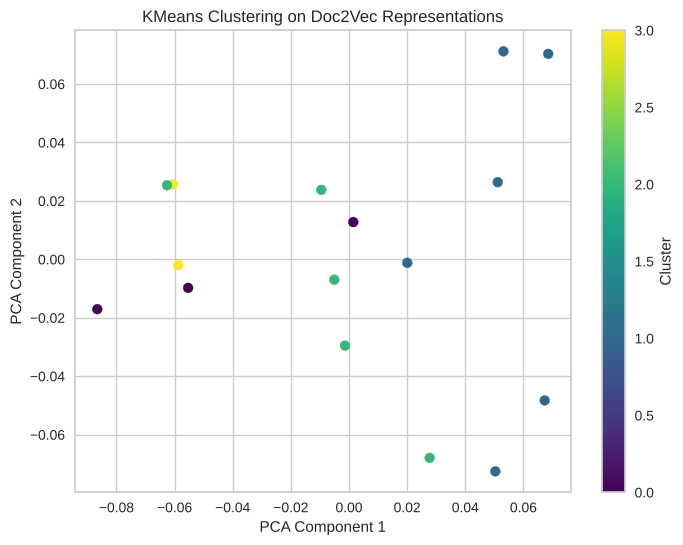

In [48]:
!pip install gensim
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# 16 toy sentences about different topics
documents = [
    "Clustering is a powerful tool in machine learning.",
    "Doc2Vec creates vector representations of documents.",
    "KMeans is a popular clustering algorithm.",
    "Machine learning applications include clustering and classification.",
    "Vectorization transforms text into numerical format.",
    "Neural networks are another type of machine learning model.",
    "Artificial intelligence is transforming the healthcare industry with predictive analytics.",
    "Quantum computing has the potential to solve complex problems faster than traditional computers.",
    "The rise of blockchain technology is revolutionizing data security and transparency.",
    "Electric vehicles are becoming more popular due to their environmental benefits and reduced operating costs.",
    "Augmented reality is enhancing user experiences in gaming and education.",
    "The Internet of Things connects devices to create smart homes and cities.",
    "Renewable energy sources like solar and wind are crucial for a sustainable future.",
    "Cybersecurity measures are essential to protect sensitive data from potential breaches.",
    "5G technology is enabling faster internet speeds and more reliable connections globally.",
    "Robotics is automating repetitive tasks, increasing efficiency across various industries.",
]

# 1. one TaggedDocument per sentence: its words + its number
tagged_docs = [TaggedDocument(doc.split(), [i]) for i, doc in enumerate(documents)]

# 2. train Doc2Vec, then one vector (10 numbers) per sentence
model = Doc2Vec(tagged_docs, vector_size=10, window=2, min_count=1, workers=4, epochs=20)
doc_vectors = np.array([model.infer_vector(doc.split()) for doc in documents])

# 3. K-Means on the document vectors
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
labels = kmeans.fit_predict(doc_vectors)

# 4. PCA: from 10 to 2 dimensions, only to draw the clusters
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(doc_vectors)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='viridis', s=50)
plt.colorbar(scatter, label='Cluster')
plt.title('KMeans Clustering on Doc2Vec Representations')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

Do the clusters capture ideas that are clear also to us? For each cluster we list its top TF-IDF words:

In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

# group the sentences by cluster
clustered_docs = {i: [] for i in range(n_clusters)}
for i, label in enumerate(labels):
    clustered_docs[label].append(documents[i])

# the top-n words of a group of sentences: TF-IDF summed over the sentences of the group
def extract_keywords(docs, top_n=5):
    vectorizer = TfidfVectorizer(stop_words='english')
    X = vectorizer.fit_transform(docs)
    feature_array = np.array(vectorizer.get_feature_names_out())
    tfidf_sorting = np.argsort(X.toarray().sum(axis=0))[::-1]
    return feature_array[tfidf_sorting][:top_n]

for cluster_id, docs in clustered_docs.items():
    print(f"Cluster {cluster_id} Topic Keywords: {', '.join(extract_keywords(docs))}")

Cluster 0 Topic Keywords: vectorization, transforms, numerical, text, format
Cluster 1 Topic Keywords: vector, tool, doc2vec, representations, machine
Cluster 2 Topic Keywords: popular, algorithm, clustering, kmeans, transparency
Cluster 3 Topic Keywords: internet, learning, include, machine, applications


# Exercise 1.4: Doc2Vec or TF-IDF?

1. Look at the sentences of each cluster above (`clustered_docs`): does each cluster have one topic?
2. Cluster the same 16 sentences with **TF-IDF** vectors (`TfidfVectorizer(stop_words='english')`) and `KMeans(n_clusters=4, n_init=10, random_state=0)`. Print the sentences of each cluster: which sentences end up together, and why?
3. Why do both representations struggle with these 16 sentences? (Think of Exercise 3.2 of Lab 1.)

> **Note: your results may differ.** Doc2Vec is trained with several threads, so its vectors (and the clusters) change a little from run to run: look at the *kind* of sentences that end up together.

In [50]:
# Your code here